# 07 · Melhorias depois do placar: o que funcionou, o que não funcionou e por quê

O placar oficial (notebook 05) deixou o C2 com 13/26 corretas no test. Este notebook conta, na
ordem, o que foi tentado para melhorar o sistema sem treinar o modelo, e como cada tentativa foi
medida.

**Protocolo.** Cada escolha foi feita num conjunto e medida em outro, ainda não usado para ela:

| Conjunto | Perguntas respondíveis | Papel |
|---|---|---|
| dev | 16 | escolher correções e modelos |
| test (T1) | 26 | placar oficial; depois das correções, só "pós-correção" |
| T2 | 18 | escrito e congelado **antes** das melhorias da Fase 8B; medido uma vez |
| T3 | 18 | escrito e congelado **depois** da escolha da M, sobre temas novos; medido uma vez |

As medidas manuais são conferências resposta a resposta: a do test pelo Pedro; as do T2, do T3 e
das correções pelo assistente, validadas pelo Pedro. No dev, a tabela usa a métrica automática
(fatos-chave), que serve para comparar variantes, não como acurácia final.

In [1]:
import json
import sys
from math import comb
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
sys.path.insert(0, str(RAIZ / "scripts"))

import matplotlib.pyplot as plt
import pandas as pd

import montar_placar as mp
from src.avaliacao.recuperacao import wilson

A = RAIZ / "avaliacao"
G = A / "runs" / "geracao"
placar = pd.read_csv(A / "placar.csv")


def ic(k, n):
    lo, hi = wilson(k, n)
    return f"{k}/{n} = {k / n:.0%} [{lo:.0%}; {hi:.0%}]"


def manual(cfg, split, metrica="acurácia manual (corretas)"):
    r = placar[(placar.config == cfg) & (placar.split == split) & (placar.metrica == metrica)].iloc[0]
    return ic(int(r.k), int(r.n))

## 1. Correções A e C (Fase 8): mais respostas, mais erros

Depois dos 5 erros, o Pedro escolheu duas correções:
- **A:** o roteador reescreve a pergunta em português padrão antes da busca e do portão;
- **C:** busca híbrida (BM25 e densa, fundidas por RRF) com o reranker bge-reranker-v2-m3.

As duas foram ajustadas no dev e depois medidas no test, já visto (pós-correção).

In [2]:
def ler_run(nome):
    with open(G / f"{nome}.jsonl", encoding="utf-8") as f:
        return [json.loads(x) for x in f if x.strip()]


conf_test = mp._yaml("conferencia_test.yaml")["itens"]
pos = mp._yaml("conferencia_pos_correcao.yaml")["itens"]["C2_AC"]
pos_pre = mp._yaml("conferencia_pos_pre.yaml", validado=False)["herdadas"]
linhas_ac = ler_run(f"C2_test_{mp.Q}_corrAC")
v_ac = mp.vereditos(linhas_ac, pos, pos_pre["mesma_resposta"] + pos_pre["mesmo_sentido"], conf_test["C2"])
corretas_ac = sum(x["veredito"] == "correta" for x in v_ac.values())
falsas_ac = sum(x["falso"] == "sim" for x in v_ac.values())
pd.DataFrame(
    {"corretas (de 26)": [manual("C2", "test"), ic(corretas_ac, 26)],
     "respostas que afirmam algo falso": [
         manual("C2", "test", "alucinação manual (respostas dadas que afirmam algo falso)"),
         ic(falsas_ac, len(v_ac))]},
    index=["C2 original (oficial)", "C2+A+C (pós-correção)"],
)

,corretas (de 26),respostas que afirmam algo falso
C2 original (oficial),13/26 = 50% [32%; 68%],6/20 = 30% [15%; 52%]
C2+A+C (pós-correção),15/26 = 58% [39%; 74%],8/23 = 35% [19%; 55%]


O C2+A+C acertou 2 perguntas a mais, mas passou a responder perguntas que antes recusava e errou
várias delas: as respostas que afirmam algo falso subiram de 6 para 8. Dois exemplos:
- **T-020:** a reescrita trocou "cortaram por erro" por "interrupção programada", e a resposta
  mudou de assunto;
- **T-007:** o reranker trouxe uma regra revogada, e a recusa virou afirmação falsa (notebook 06).

**Lição:** reescrever toda pergunta muda o sentido de algumas. Na etapa seguinte, a reescrita
ficou só para as perguntas de voz (correção V).

## 2. Fase 8B no dev: novas correções e modelos maiores

Em vez de treinar o modelo, o Pedro escolheu melhorar o pipeline e testar modelos que raciocinam
melhor, aceitando respostas mais lentas. Antes de qualquer ajuste, o T2 foi escrito e congelado.

Correções novas:
- **D:** mostrar as notas de revogação e marcar os incisos revogados;
- **E:** atos normativos antes das páginas com alerta, e alerta reforçado;
- **F:** autoverificação da resposta contra os trechos citados (uma chamada a mais ao LLM);
- **V:** a reescrita da correção A, só para perguntas de voz.

Modelos testados no dev: qwen3 4B em q8, qwen3 4B thinking, qwen3 8B (com e sem raciocínio) e
qwen3.5 9B. A GPU tem 6 GB; acima de cerca de 5,9 GB, parte do modelo vai para a CPU.

In [3]:
dev = []
for arq in sorted(G.glob("C2_dev_*.meta.json")):
    m = json.loads(arq.read_text(encoding="utf-8"))
    r = m["resumo"]
    corr = m.get("correcoes") or "—"
    dev.append({
        "modelo": m["modelo"].replace("-instruct-2507", "").replace("-2507", ""),
        "correções": corr + (" (raciocínio)" if arq.name.endswith("_think.meta.json") else ""),
        "acurácia automática (de 16)": r["acuracia"]["k"],
        "recusa indevida": r["recusa_indevida"]["k"],
        "agenda (de 3)": r["acerto_dinamicas"]["k"],
        "JSON válido 1ª tentativa": f"{r['json_valido_1a']['k']}/{r['json_valido_1a']['n']}",
        "latência p95 (s)": r["latencia_p95_s"],
        "VRAM pico (GB)": round(m["vram_pico_mib"] / 1024, 1),
    })
dev = pd.DataFrame(dev).sort_values(["modelo", "correções"]).reset_index(drop=True)
dev

,modelo,correções,acurácia automática (de 16),recusa indevida,agenda (de 3),JSON válido 1ª tentativa,latência p95 (s),VRAM pico (GB)
0,qwen3.5:9b-q4_K_M,CDEFV,13,2,3,19/19,160.97,6.0
1,qwen3:4b-q4_K_M,A,10,2,3,20/20,16.13,4.0
2,qwen3:4b-q4_K_M,AC,13,2,3,20/20,17.59,5.6
3,qwen3:4b-q4_K_M,C,12,3,3,17/17,12.06,5.4
4,qwen3:4b-q4_K_M,CDE,12,3,3,17/17,12.90,5.5
5,qwen3:4b-q4_K_M,CDEF,13,3,3,17/17,24.24,5.5
6,qwen3:4b-q4_K_M,CDEFV,14,1,3,19/19,23.70,5.7
7,qwen3:4b-q4_K_M,CDEV,14,1,3,19/19,16.99,5.9
8,qwen3:4b-q4_K_M,DE,11,3,3,17/17,13.80,4.2
9,qwen3:4b-q4_K_M,F,10,4,3,17/17,25.33,4.2


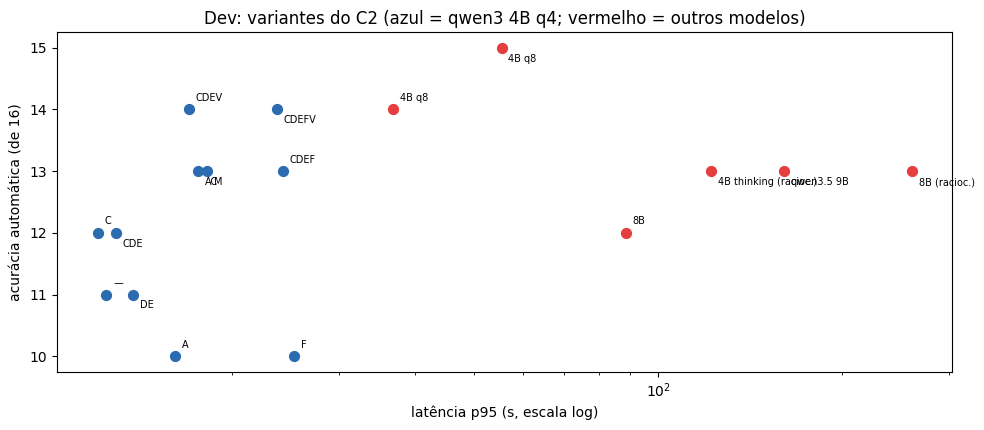

In [4]:
CURTO = {"qwen3:4b-q8_0": "4B q8", "qwen3:4b-thinking-q4_K_M": "4B thinking",
         "qwen3:8b-q4_K_M": "8B", "qwen3.5:9b-q4_K_M": "qwen3.5 9B"}
fig, ax = plt.subplots(figsize=(10, 4.4))
for n, (_, r) in enumerate(dev.iterrows()):
    base = r["modelo"].startswith("qwen3:4b-q4")
    x, y = r["latência p95 (s)"], r["acurácia automática (de 16)"]
    ax.scatter(x, y, s=50, color="#2b6cb0" if base else "#e53e3e")
    rotulo = r["correções"] if base else f"{CURTO[r['modelo']]}" + (" (racioc.)" if "racioc" in r["correções"] else "")
    ax.annotate(rotulo, (x, y), fontsize=7, xytext=(5, 6 if n % 2 else -10), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("latência p95 (s, escala log)")
ax.set_ylabel("acurácia automática (de 16)")
ax.set_title("Dev: variantes do C2 (azul = qwen3 4B q4; vermelho = outros modelos)")
plt.tight_layout()
plt.show()

**Modelos maiores não compensaram.** Foram de 2 a 15 vezes mais lentos que o CDEV do 4B q4 (p95 de
37 s a 260 s, contra 17 s), porque não cabem inteiros na GPU de 6 GB, e não acertaram mais:
- o 8B e o qwen3.5 9B ficaram em 12 e 13 de 16, e o 8B errou uma pergunta da agenda;
- o 4B thinking ficou em 13/16 e gerou 2 JSON inválidos na 1ª tentativa;
- o 4B q8 empatou com o q4 sem a F (14/16), com o dobro da latência, e afirmou na T-035 que o
  caso "é uma situação de serviço essencial", o que não estava nos trechos. Com a F, ele chegou a
  15/16 na métrica automática, mas a F foi descartada pelo motivo abaixo.

**A autoverificação (F) foi descartada.** Na leitura das respostas do dev, ela não acrescentou
acertos e criou duas afirmações falsas que a métrica automática contou como acertos:
- **T-055:** o verificador apontou um erro de data que não existia, e o reparo trocou "sim, há
  parada das 9h às 13h" por "não há parada";
- **T-010:** o reparo levou a "não tem desconto de 100%".

**Escolhido no dev:** qwen3 4B q4 com C, D, E e V (o "CDEV"), com 14/16, uma recusa indevida e p95
de 17 s.

## 3. O T2: o CDEV não se repetiu

O T2 (24 perguntas, escrito antes das melhorias) mediu o C2 original e o CDEV uma única vez.

In [5]:
falso = "alucinação manual (respostas dadas que afirmam algo falso)"
pd.DataFrame(
    {"dev (automática, de 16)": ["11/16", "14/16"],
     "T2: corretas (manual)": [manual("C2", "test2"), manual("C2+CDEV", "test2")],
     "T2: afirmam algo falso": [manual("C2", "test2", falso), manual("C2+CDEV", "test2", falso)]},
    index=["C2 original", "C2+CDEV"],
)

,"dev (automática, de 16)",T2: corretas (manual),T2: afirmam algo falso
C2 original,11/16,10/18 = 56% [34%; 75%],4/16 = 25% [10%; 49%]
C2+CDEV,14/16,10/18 = 56% [34%; 75%],6/16 = 38% [18%; 61%]


No dev, o CDEV tinha 3 acertos a mais; no T2, empatou com o C2 original (10/18) e afirmou algo
falso em mais respostas (6 contra 4). Com 16 perguntas, uma diferença de 3 está dentro do acaso:
as correções foram escolhidas porque consertavam aquelas 16, não porque melhoravam o sistema.

**Lição:** uma melhoria escolhida num conjunto pequeno precisa ser confirmada num conjunto que não
participou da escolha. Sem o T2, o CDEV teria entrado no relatório como ganho.

## 4. Opção B: melhorar só a busca

A maioria das falhas vinha de o trecho certo não chegar ao modelo. A opção B mediu 12 variantes de
busca nas 60 perguntas respondíveis do T1 (dev e test) e do T2, sem gerar respostas:
- **denso:** a busca original (bge-m3);
- **hib_rr:** híbrida (BM25 e densa, RRF) com reranker;
- **mq:** multiconsulta, com a pergunta original e 3 reformulações feitas pelo LLM;
- **faq:** com peso menor para as páginas explicativas;
- **k3 / k5:** 3 ou 5 trechos entregues ao modelo.

A coluna `recall` conta as perguntas com pelo menos um trecho gold entre os entregues.

,variante,recall (de 60),IC 95%,recall no T2,voz (de 9),portão: respondíveis aceitas,portão: fora do domínio aceitas
0,denso_k3,44/60,[0.61; 0.83],12/18,3/9,65/75,3/28
1,denso_k5,46/60,[0.65; 0.86],13/18,4/9,65/75,3/28
2,hib_rr_k3,46/60,[0.65; 0.86],13/18,6/9,65/75,3/28
3,hib_rr_k5,50/60,[0.72; 0.91],13/18,6/9,65/75,3/28
4,hib_rr_faq_k3,41/60,[0.56; 0.79],7/18,2/9,65/75,3/28
5,hib_rr_faq_k5,49/60,[0.70; 0.89],10/18,6/9,65/75,3/28
6,mq_k3,45/60,[0.63; 0.84],11/18,5/9,74/75,8/28
7,mq_k5,48/60,[0.68; 0.88],12/18,7/9,74/75,8/28
8,mq_rr_k3,48/60,[0.68; 0.88],15/18,6/9,74/75,8/28
9,mq_rr_k5,52/60,[0.76; 0.93],16/18,7/9,74/75,8/28


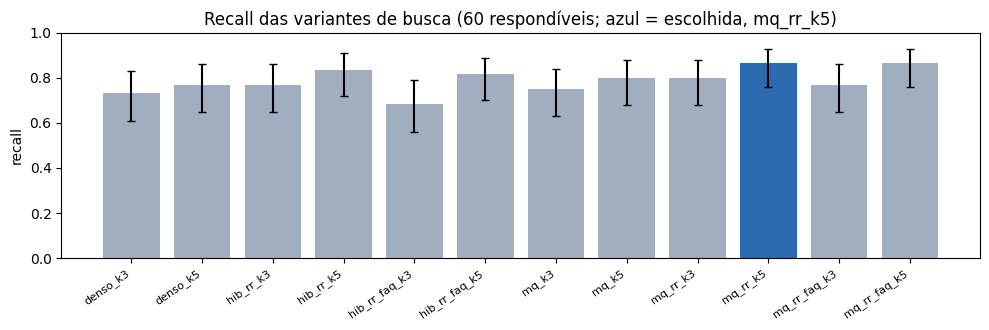

In [6]:
var = pd.read_csv(A / "busca" / "variantes.csv")
cols = {"variante": "variante", "recall": "recall (de 60)", "ic95": "IC 95%", "recall_T2": "recall no T2",
        "voz": "voz (de 9)", "portao_respondiveis": "portão: respondíveis aceitas",
        "portao_fora_aceitas": "portão: fora do domínio aceitas"}
display(var[list(cols)].rename(columns=cols))
fig, ax = plt.subplots(figsize=(10, 3.4))
cores_v = ["#2b6cb0" if v == "mq_rr_k5" else "#a0aec0" for v in var.variante]
lo = var.recall_taxa - var.ic95.str.extract(r"\[([\d.]+);")[0].astype(float)
hi = var.ic95.str.extract(r"; ([\d.]+)\]")[0].astype(float) - var.recall_taxa
ax.bar(var.variante, var.recall_taxa, color=cores_v, yerr=[lo, hi], capsize=3)
ax.set_ylim(0, 1)
ax.set_ylabel("recall")
ax.set_title("Recall das variantes de busca (60 respondíveis; azul = escolhida, mq_rr_k5)")
plt.xticks(rotation=35, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

A **multiconsulta com reranker e 5 trechos (mq_rr_k5)** foi a melhor: recall de 52/60 (87%) contra
44/60 (73%) da busca original, com o maior ganho nas perguntas de voz (7/9 contra 3/9) e no T2
(16/18 contra 12/18). Empatou no total com a mesma variante com peso menor para as páginas
explicativas (mq_rr_faq_k5), mas teve mais recall no T2 (16 contra 14). Ela virou a **correção M**, com um τ próprio para o portão (0,6635, para que
no máximo 5% das perguntas fora do domínio passem pelo maior cosseno entre as reformulações).

No test e no T2, o C2+M acertou mais que o C2 original (19/26 contra 13/26; 12/18 contra 10/18).
Mas a M foi escolhida olhando a busca justamente nesses dois conjuntos, então esses números são
otimistas. Para medi-la sem esse viés, foi escrito o T3.

## 5. O T3: a medida limpa da multiconsulta

O T3 tem 24 perguntas sobre trechos que nenhum conjunto anterior usou como gabarito, com a mesma
composição do T2. Foi congelado com hash antes de qualquer execução, e a regra declarada antes
foi: o sistema não muda depois do T3. O C2 original e o C2+M rodaram uma vez cada.

In [7]:
from src.avaliacao.casos import carregar_test3

t3 = mp._yaml("conferencia_t3.yaml")
v2 = {i: x["veredito"] == "correta" for i, x in t3["itens"]["C2"].items()}
vm = {i: x["veredito"] == "correta" for i, x in t3["itens"]["C2M"].items()}
ids = sorted(c.id for c in carregar_test3() if c.tipo in mp.RESPONDIVEIS)
so_m = [i for i in ids if vm.get(i, False) and not v2.get(i, False)]
so_c2 = [i for i in ids if v2.get(i, False) and not vm.get(i, False)]
b, c = len(so_m), len(so_c2)
p = min(1, 2 * sum(comb(b + c, k) for k in range(min(b, c) + 1)) / 2 ** (b + c))
display(pd.DataFrame(
    {"corretas (de 18)": [manual("C2", "test3"), manual("C2+M", "test3")],
     "afirmam algo falso": [manual("C2", "test3", falso), manual("C2+M", "test3", falso)],
     "recusas indevidas": [len(t3["recusas_indevidas"]["C2"]), len(t3["recusas_indevidas"]["C2M"])]},
    index=["C2 original", "C2+M"]))
print(f"Só o C2+M acerta: {so_m}")
print(f"Só o C2 acerta: {so_c2}")
print(f"Teste de McNemar exato: p = {p:.2f}")

,corretas (de 18),afirmam algo falso,recusas indevidas
C2 original,9/18 = 50% [29%; 71%],2/15 = 13% [4%; 38%],3
C2+M,14/18 = 78% [55%; 91%],2/16 = 12% [3%; 36%],2


Só o C2+M acerta: ['T3-03', 'T3-09', 'T3-10', 'T3-11', 'T3-13', 'T3-14', 'T3-18']
Só o C2 acerta: ['T3-06', 'T3-15']
Teste de McNemar exato: p = 0.18


No T3, o C2+M acertou 14/18 contra 9/18. É a única melhoria que se repetiu fora de onde foi
escolhida, e a direção é a mesma nos três conjuntos (somados: 45/62 contra 32/62). O T3 sozinho é
pequeno para afirmar a diferença com 95% de confiança (McNemar acima), e as afirmações falsas
ficaram parecidas (2/16 contra 2/15). No dev, a M tinha ficado em 13/16, abaixo do CDEV (14/16):
o ranking do dev não previu qual correção se sustentaria.

Um achado do T3: na T3-23, o modelo citou um registro da agenda com "13:00 (17h)", e o original diz
"13:00 (13h)". A resposta deu o horário certo, mas a comparação aproximada das citações (90% de
semelhança) aceita um número trocado. Ficou registrado, sem correção, pela regra do T3.

## 6. Resumo

| Tentativa | Onde foi escolhida | Medida fora da escolha | Resultado |
|---|---|---|---|
| A + C (reescrita e reranker) | dev | test (já visto) | +2 acertos, +2 respostas falsas; reescrita ficou só para voz |
| Modelos maiores (q8, thinking, 8B, 9B) | dev | — | não acertaram mais e foram de 2 a 15 vezes mais lentos |
| Autoverificação (F) | dev | — | descartada: criou afirmações falsas |
| CDEV | dev | T2 | não se repetiu (10/18 contra 10/18) |
| **Multiconsulta (M)** | busca no test e no T2 | **T3** | **14/18 contra 9/18; sistema oficial** |

**O que aprendemos.**
1. **Escolher no mesmo conjunto em que se mede engana.** O CDEV parecia o melhor no dev e empatou
   no T2. Só a M foi confirmada num conjunto escrito depois da escolha.
2. **A métrica automática não basta.** Ela contou como acertos as respostas falsas criadas pela
   autoverificação; a leitura resposta a resposta foi o que mostrou o problema.
3. **Modelo maior não é saída numa GPU de 6 GB.** O ganho, quando houve, não pagou a latência.
4. **Melhorar a busca ajuda até certo ponto.** A M trouxe o trecho certo para mais perguntas, mas os
   erros que sobram são de interpretação: prazo de outra situação, regra geral sem a exceção,
   regra revogada (notebook 06). Os próximos passos seriam identificar a situação do consumidor
   antes de escolher o prazo e tirar da base o texto revogado.